In [1]:
%matplotlib qt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.base import clone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
sns.set_theme(style='white')

In [2]:
df = pd.read_csv('../CSVs/08_model_ready_dataset.csv').drop(columns=['Unnamed: 0'])
len(df[df.isna().any(axis=1)])

0

In [3]:
# Changing columns names for more readability
df.columns = [
    'village_code', 'visit_month', 'spray_status',
    'total_residents',
    'clinic_tests', 'total_rdts',
    'avg_distance_to_health_facility_km', 'incidence_per_1000',
    'positivity_rate', 'dist_missing', 'rainfall', 'rainfall_total',
    'humidity', 'temp', 'max_temp', 'min_temp', 'temp_range',
    'prev_rainfall', 'prev2_rainfall', 'prev3_rainfall', 'prev4_rainfall',
    'prev_rainfall_total', 'prev2_rainfall_total', 'prev3_rainfall_total',
    'prev4_rainfall_total', 'prev_humidity', 'prev2_humidity',
    'prev3_humidity', 'prev4_humidity', 'prev_temp', 'prev2_temp',
    'prev3_temp', 'prev4_temp', 'prev_max_temp', 'prev2_max_temp',
    'prev3_max_temp', 'prev4_max_temp', 'prev_min_temp', 'prev2_min_temp',
    'prev3_min_temp', 'prev4_min_temp', 'prev_temp_range',
    'prev2_temp_range', 'prev3_temp_range', 'prev4_temp_range',
    'prev_incidence_per_1000', 'prev_u5_incidence_per_1000', 'mpi'
]

In [4]:
months = df['visit_month'].unique()
lengths = []
for i, x in enumerate(months):
    lengths.append(len(df[df['visit_month'] == x]))
# This shows a very average distribution. No imbalances. Nice

In [5]:
df['avg_distance_to_health_facility_km'].max()

np.float64(30.1)

In [6]:
village_codes = df['village_code'].unique()
split_point_village = int(len(village_codes) * .8)
village_bool = df['village_code'] <= village_codes[split_point_village]
len(df[village_bool]), len(df[~village_bool])

(3002, 674)

In [7]:
dates = sorted(df['visit_month'].unique())
split_point_date = int(len(dates) * 0.7)

month_bool = df['visit_month'].isin(dates[:split_point_date])

len(df[month_bool]), len(df[~month_bool])

(2463, 1213)

In [8]:
def chrono(chrono_bool):
    """
    Function for specifying which boolean to use for the (chronological or spatial) split
    """
    return month_bool if chrono_bool else village_bool

In [9]:
# Check split ratio above
target_columns = ['incidence_per_1000'] # These are the columns our model tries to predict
# And these are poor or useless columns that carry information about which villages have suffered epidemics before
# Causing it to overfit by predicting historical average
useless_columns = ['prev_u5_incidence_per_1000', 'total_residents', 'visit_month', 'village_code', 'avg_distance_to_health_facility_km', 'clinic_tests',
                   'rainfall', 'rainfall_total', 'total_rdts', 'positivity_rate'] \
                + ['prev_rainfall', 'prev_rainfall_total', 'prev_min_temp', 'prev_max_temp', 'prev_temp', 'prev_humidity'] \
                + ['prev2_rainfall_total', 'prev3_rainfall_total', 'prev4_rainfall_total', 'prev_temp_range', 'prev2_temp_range',\
                   'prev3_temp_range', 'prev4_temp_range', 'temp_range']
                 # + ['humidity', 'temp', 'max_temp', 'min_temp', 'temp_range', 'total_rdts']
# Train data becomes the majority (80%)
X_train = df[chrono(1)]
y_train = X_train[target_columns]
# Test data becomes the minority (20%)
X_test = df[~chrono(1)]
y_test = X_test[target_columns]
# We finally drop the target columns from the X data
X_train = X_train.drop(columns=target_columns + useless_columns) # We also don't need 'visit_month' anymore it isn't important in training
X_test = X_test.drop(columns=target_columns + useless_columns)

In [10]:
# Rolling-origin validation: train on months before m, validate on month m (last 4 training months)
train_months = df[chrono(1)]['visit_month'].values
months_sorted = sorted(set(train_months))
cv_splits = [(np.where(train_months < m)[0], np.where(train_months == m)[0])
             for m in months_sorted[-4:]]
print([str(m)[:7] for m in months_sorted[-4:]])

['2017-12', '2018-01', '2018-02', '2018-03']


In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
model = RandomForestRegressor(max_depth=10, random_state=42).fit(X_train_scaled, np.ravel(y_train))

In [13]:
linear = LinearRegression().fit(X_train_scaled, y_train)

In [14]:
dt = DecisionTreeRegressor(random_state=42).fit(X_train_scaled, y_train)

In [15]:
knn = KNeighborsRegressor().fit(X_train_scaled, y_train)

In [16]:
ridge = GridSearchCV(
    Ridge(),
    param_grid={ 'alpha': np.logspace(-4, 4, 25)},
    cv=cv_splits,
    n_jobs=2,
)
ridge.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'alpha': array([1.0000...00000000e+04])}
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [17]:
lasso = GridSearchCV(
    Lasso(),
    param_grid={ 'alpha': np.logspace(-4, 2, 25) },
    cv=cv_splits,
    n_jobs=2,
)
lasso.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'alpha': array([1.0000...00000000e+02])}
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

In [18]:
elasticnet = GridSearchCV(
    ElasticNet(max_iter=10000),
    param_grid={'alpha': np.logspace(-2, 2, 15), 'l1_ratio': [.1, .3, .5, .7, .9, 1.0]},
    cv=cv_splits,
    n_jobs=2,
)
elasticnet.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",ElasticNet(max_iter=10000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.0000...00000000e+02]), 'l1_ratio': [0.1, 0.3, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...shape=(1775,)), ...), (array([ 0, ...shape=(1942,)), ...), ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable

In [19]:
# Note that this is a way less stable and, somewhat, less reliable of a model because it loses most of its predictive power on a chonological split.
knn_metrics = [100 * r2_score(y_test, knn.predict(X_test_scaled)), mean_absolute_error(y_test, knn.predict(X_test_scaled)), \
           root_mean_squared_error(y_test, knn.predict(X_test_scaled))]

# Not that this is also way less stable and, somewhat, less reliable of a model because it loses most of its predictive power on a chonological split.
linear_metrics = [100 * r2_score(y_test, linear.predict(X_test_scaled)), mean_absolute_error(y_test, linear.predict(X_test_scaled)), \
           root_mean_squared_error(y_test, linear.predict(X_test_scaled))]

# This one is way more reliable
rf_metrics = [100 * r2_score(y_test, model.predict(X_test_scaled)), mean_absolute_error(y_test, model.predict(X_test_scaled)), \
          root_mean_squared_error(y_test, model.predict(X_test_scaled))]

metrics_dt = [100 * r2_score(y_test, dt.predict(X_test_scaled)), mean_absolute_error(y_test, dt.predict(X_test_scaled)), \
             root_mean_squared_error(y_test, dt.predict(X_test_scaled))]

metrics_ridge = [100 * r2_score(y_test, ridge.predict(X_test_scaled)), mean_absolute_error(y_test, ridge.predict(X_test_scaled)), \
                 root_mean_squared_error(y_test, ridge.predict(X_test_scaled))]

metrics_lasso = [100 * r2_score(y_test, lasso.predict(X_test_scaled)), mean_absolute_error(y_test, lasso.predict(X_test_scaled)), \
                 root_mean_squared_error(y_test, lasso.predict(X_test_scaled))]

metrics_enet = [100 * r2_score(y_test, elasticnet.predict(X_test_scaled)), mean_absolute_error(y_test, elasticnet.predict(X_test_scaled)), \
                root_mean_squared_error(y_test, elasticnet.predict(X_test_scaled))]

In [20]:
print(f"""
KNN: {knn_metrics}\nLR: {linear_metrics}\nRF: {rf_metrics}\nDT: {metrics_dt}\nRidge: {metrics_ridge}\nLasso: {metrics_lasso}\nElasticNet: {metrics_enet}
""")


KNN: [56.78728446452897, 18.652232400785493, 32.329985949849764]
LR: [33.742225704067174, 30.197649722343424, 40.03300198427783]
RF: [63.73445382699732, 17.500398809865505, 29.617394338013227]
DT: [42.8208152266737, 23.287454278466093, 37.189360988004516]
Ridge: [68.87221341678058, 17.028402779916682, 27.439352356477002]
Lasso: [68.57097179037088, 17.429339240017864, 27.571805926223686]
ElasticNet: [68.29908538811105, 17.55592285922445, 27.69080827563747]



In [21]:
print(elasticnet.best_estimator_.n_iter_, 'of', elasticnet.best_estimator_.max_iter)

67 of 10000


In [26]:
# Sample data
data = [
    knn_metrics,
    rf_metrics,
    metrics_dt,
    linear_metrics,
    metrics_ridge,
    metrics_lasso,
    metrics_enet
]

# New labels for the groups (models)
group_labels = ['k-Nearest Neighbors', 'Random Forest', 'Decision Trees', 'Linear Regression', 'Ridge Regression', 'Lasso Regression', 'ElasticNet']
# New labels for the elements (metrics)
element_labels = ['R2 * 100 (0 - 100)', 'MAE', 'RMSE']
# Set the width of the bars
bar_width = 0.25
# Set the positions of the bar groups on the x-axis
x_positions = np.arange(len(group_labels))
# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the bars for each of the three elements in all groups
for i in range(3):
    values = [array[i] for array in data]
    ax.bar(x_positions + i * bar_width, values, bar_width, label=element_labels[i])

# Set the title and labels
ax.set_title('Model Performance Metrics Comparison')
ax.set_xlabel('Models')
ax.set_ylabel('Metric Value')

# Set the x-axis tick positions and labels
ax.set_xticks(x_positions + bar_width)
ax.set_xticklabels(group_labels, rotation=45, ha='right', fontsize=7)
# Add a legend to distinguish the elements
ax.legend()

plt.show()

In [23]:
coef_df = pd.DataFrame({
    'features': X_train.columns,
    'coefs': lasso.best_estimator_.coef_
})
coef_df.sort_values('coefs')
plt.figure(figsize=(10, 6))
plt.xlabel('Features'); plt.ylabel('Importances')
plt.bar(coef_df['features'], coef_df['coefs'])
plt.xticks(rotation=45, ha='right', fontsize=7)
coef_df[coef_df['coefs'] == 0]['features']

2           humidity
3               temp
4           max_temp
8     prev4_rainfall
9     prev2_humidity
10    prev3_humidity
11    prev4_humidity
12        prev2_temp
14        prev4_temp
15    prev2_max_temp
16    prev3_max_temp
17    prev4_max_temp
20    prev4_min_temp
Name: features, dtype: str

In [24]:
labels = [c.replace('mpi', 'village_historical_incidence') for c in X_test.columns]
importances = model.feature_importances_
plt.figure(figsize=(20, 8))
plt.bar(labels, importances)                                                            
plt.xlabel('Features'); plt.ylabel('Importance (mean decrease in impurity)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

In [27]:
coef_df = pd.DataFrame({
    'features': [c.replace('mpi', 'village_historical_incidence') for c in X_train.columns],
    'coefs': lasso.best_estimator_.coef_
})
plt.figure(figsize=(10, 6))
plt.xlabel('Features'); plt.ylabel('Coefficient (per 1 SD change)')
plt.bar(coef_df['features'], coef_df['coefs'])
plt.axhline(0, color='black', linewidth=0.8)                                           # NEW: zero line
plt.xticks(rotation=45, ha='right', fontsize=7)
ax = plt.gca()
ax.tick_params(axis='x', labelsize=7, rotation=45)
plt.tight_layout()
plt.savefig('fig3_lasso_coefficients.png', dpi=300, bbox_inches='tight')

In [26]:
print(f'Lasso kept {len(lasso.best_estimator_.coef_) - np.count_nonzero(lasso.best_estimator_.coef_ == 0)} of 23 features')

Lasso kept 10 of 23 features


In [27]:
coef_df = pd.DataFrame({
    'features': X_train.columns,
    'coefs': ridge.best_estimator_.coef_
})
coef_df.sort_values('coefs')
plt.figure(figsize=(10, 6))
plt.xlabel('Features'); plt.ylabel('Importances')
plt.bar(coef_df['features'], coef_df['coefs'])
plt.xticks(rotation=45, ha='right', fontsize=7)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, 'spray_status'),
  Text(1, 0, 'dist_missing'),
  Text(2, 0, 'humidity'),
  Text(3, 0, 'temp'),
  Text(4, 0, 'max_temp'),
  Text(5, 0, 'min_temp'),
  Text(6, 0, 'prev2_rainfall'),
  Text(7, 0, 'prev3_rainfall'),
  Text(8, 0, 'prev4_rainfall'),
  Text(9, 0, 'prev2_humidity'),
  Text(10, 0, 'prev3_humidity'),
  Text(11, 0, 'prev4_humidity'),
  Text(12, 0, 'prev2_temp'),
  Text(13, 0, 'prev3_temp'),
  Text(14, 0, 'prev4_temp'),
  Text(15, 0, 'prev2_max_temp'),
  Text(16, 0, 'prev3_max_temp'),
  Text(17, 0, 'prev4_max_temp'),
  Text(18, 0, 'prev2_min_temp'),
  Text(19, 0, 'prev3_min_temp'),
  Text(20, 0, 'prev4_min_temp'),
  Text(21, 0, 'prev_incidence_per_1000'),
  Text(22, 0, 'mpi')])

In [28]:
tr = df[chrono(1)]
# 1. Split: expect 2463 training rows, last training month 2018-03
print('1. Train rows:', len(tr), '| last training month:', str(tr['visit_month'].max())[:7])

# 2. Climate: Jan 2017 must be temp 27.23, humidity 85.07, rainfall 7.11 (Mopeia town cell)
print('2. Jan 2017 climate:', df[df['visit_month'].astype(str).str.startswith('2017-01')][['temp', 'humidity', 'rainfall']].iloc[0].to_dict())

# 3. MPI must be "past incidence only": correlation with a fresh rebuild must be 1.0000
d = df.sort_values(['village_code', 'visit_month'])
g = d.groupby('village_code')['incidence_per_1000']
past = ((g.cumsum() - d['incidence_per_1000']) / g.cumcount().replace(0, np.nan)).fillna(tr['incidence_per_1000'].mean()).loc[df.index]
print('3. mpi vs past-incidence rebuild (must be 1.0000):', round(np.corrcoef(past, df['mpi'])[0, 1], 4))

# 4. Expected correlation for Figure 2: 0.68
print('4. mpi vs incidence on training months (expect 0.68):', round(tr['mpi'].corr(tr['incidence_per_1000']), 2))

1. Train rows: 2463 | last training month: 2018-03
2. Jan 2017 climate: {'temp': 27.23, 'humidity': 85.07, 'rainfall': 7.11}
3. mpi vs past-incidence rebuild (must be 1.0000): 1.0
4. mpi vs incidence on training months (expect 0.68): 0.68


In [29]:
df['dist_missing'].corr(df['incidence_per_1000'])

np.float64(0.09474967558354298)

In [30]:
def plot_bivariate_correlations(df, target_col, method='pearson'):
  """Computes and plots bivariate correlations between each feature and the target column.

  Parameters:
  - df: pandas DataFrame containing your features and target
  - target_col: string name of your target column (e.g., 'incidence_per_1000')
  - method: 'pearson' (linear) or 'spearman' (monotonic/rank-based)
  """
  features = df.drop(columns=[target_col])
  correlations = features.corrwith(df[target_col], method=method).dropna()
  correlations = correlations.sort_values()

  plt.figure(figsize=(10, max(6, len(correlations) * 0.35)))

  colors = ['crimson' if val < 0 else 'steelblue' for val in correlations]

  ax = sns.barplot(
      x=correlations.values, y=correlations.index, palette=colors, hue=None
  )

  plt.axvline(0, color='black', linewidth=1, linestyle='--')

  plt.title(
      f'Bivariate {method.capitalize()} Correlation with {target_col}',
      fontsize=14,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel(f'Correlation Coefficient ({method})', fontsize=12)
  plt.ylabel('Features', fontsize=12)

  for p in ax.patches:
    width = p.get_width()
    ha = 'left' if width >= 0 else 'right'
    offset = 0.01 if width >= 0 else -0.01
    ax.annotate(
        f'{width:.2f}',
        (width + offset, p.get_y() + p.get_height() / 2.0),
        ha=ha,
        va='center',
        fontsize=9,
        color='black',
        fontweight='semibold',
    )

  plt.tight_layout()
  plt.show()


plot_bivariate_correlations(
    df[chrono(1)].drop(columns=useless_columns).rename(columns={'mpi': 'village_historical_incidence'}),
    target_col='incidence_per_1000', method='pearson')

C:\Users\Milky\AppData\Local\Temp\ipykernel_8576\3926143212.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
findfont: Failed to find font weight semibold for Arial, now using 700.


In [30]:
bv1_pred = []
for x in range(1, len(X_train_scaled) + 1):
    bv1_pred.append(df[chrono(1)]['incidence_per_1000'].mean())
bv1_pred = np.array(bv1_pred)

# ==========================================
# CORRECTED TEST-SET BASELINES
# ==========================================

global_mean_pred = np.full(len(y_test), float(np.ravel(y_train).mean()))
metrics_global_mean = [
    100 * r2_score(y_test, global_mean_pred),
    mean_absolute_error(y_test, global_mean_pred),
    root_mean_squared_error(y_test, global_mean_pred)
]

village_means = df[chrono(1)].groupby('village_code')['incidence_per_1000'].mean().to_dict()
village_mean_pred = df[~chrono(1)]['village_code'].map(village_means).fillna(float(np.ravel(y_train).mean()))
metrics_village_mean = [
    100 * r2_score(y_test, village_mean_pred),
    mean_absolute_error(y_test, village_mean_pred),
    root_mean_squared_error(y_test, village_mean_pred)
]
persistence_pred = df[~chrono(1)]['prev_incidence_per_1000']
metrics_persistence = [
    100 * r2_score(y_test, persistence_pred),
    mean_absolute_error(y_test, persistence_pred),
    root_mean_squared_error(y_test, persistence_pred)
]

print("=== CORRECTED BASELINES (TEST SET) ===")
print(f"Global Mean Baseline   -> R2: {metrics_global_mean[0]:.2f}%, MAE: {metrics_global_mean[1]:.2f}, RMSE: {metrics_global_mean[2]:.2f}")
print(f"Village-Mean Baseline  -> R2: {metrics_village_mean[0]:.2f}%, MAE: {metrics_village_mean[1]:.2f}, RMSE: {metrics_village_mean[2]:.2f}")
print(f"Persistence Baseline   -> R2: {metrics_persistence[0]:.2f}%, MAE: {metrics_persistence[1]:.2f}, RMSE: {metrics_persistence[2]:.2f}")

=== CORRECTED BASELINES (TEST SET) ===
Global Mean Baseline   -> R2: -0.93%, MAE: 29.57, RMSE: 49.41
Village-Mean Baseline  -> R2: 47.25%, MAE: 20.97, RMSE: 35.72
Persistence Baseline   -> R2: 59.66%, MAE: 18.55, RMSE: 31.24


In [31]:
train_rows, test_rows = df[chrono(1)], df[~chrono(1)]
base_cols = [c for c in X_train.columns if c != 'mpi']

ohe = pd.get_dummies(df['village_code'], prefix='v').astype(float)
ohe_train, ohe_test = ohe.loc[train_rows.index], ohe.loc[test_rows.index]

feature_sets = {
    'No village info': (X_train[base_cols], X_test[base_cols]),
    'MPI':             (X_train[base_cols + ['mpi']], X_test[base_cols + ['mpi']]),
    'One-hot':         (pd.concat([X_train[base_cols], ohe_train], axis=1),
                        pd.concat([X_test[base_cols], ohe_test], axis=1)),
}

y_tr, y_true = np.ravel(y_train), np.ravel(y_test)
models = {'LR': linear, 'Ridge': ridge, 'Lasso': lasso, 'RF': model}
preds, rows = {}, []
for set_name, (Xtr, Xte) in feature_sets.items():
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    for m_name, est in models.items():
        p = np.ravel(clone(est).fit(Xtr_s, y_tr).predict(Xte_s))
        preds[(set_name, m_name)] = p
        rows.append({'Model': m_name, 'Features': set_name, 'n_features': Xtr.shape[1],
                     'R2': 100 * r2_score(y_true, p),
                     'MAE': mean_absolute_error(y_true, p),
                     'RMSE': root_mean_squared_error(y_true, p)})

table = pd.DataFrame(rows)
print(table.pivot(index='Model', columns='Features', values='R2')
           [['No village info', 'MPI', 'One-hot']].round(2))
print('Number of features:', table.groupby('Features')['n_features'].first().to_dict())

villages = test_rows['village_code'].values
uv = np.unique(villages)
rows_of = {v: np.where(villages == v)[0] for v in uv}
rng = np.random.default_rng(0)
samples = [np.concatenate([rows_of[v] for v in rng.choice(uv, len(uv))]) for _ in range(2000)]
print('\nMPI minus One-hot (R2 points), 95% CI:')
for m_name in models:
    a, b = preds[('MPI', m_name)], preds[('One-hot', m_name)]
    diff = 100 * (r2_score(y_true, a) - r2_score(y_true, b))
    boot = [100 * (r2_score(y_true[i], a[i]) - r2_score(y_true[i], b[i])) for i in samples]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f'  {m_name:6s} {diff:+.2f}   [{lo:+.2f}, {hi:+.2f}]')

Features  No village info    MPI  One-hot
Model                                    
LR                  28.44  33.74    34.28
Lasso               65.79  68.57    67.33
RF                  63.11  63.73    64.26
Ridge               67.38  68.87    65.88
Number of features: {'MPI': 23, 'No village info': 22, 'One-hot': 207}

MPI minus One-hot (R2 points), 95% CI:
  LR     -0.53   [-4.38, +2.67]
  Ridge  +2.99   [+0.51, +6.23]
  Lasso  +1.24   [-0.43, +3.84]
  RF     -0.53   [-3.98, +5.40]


In [32]:
import warnings; from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)      # NEW: hide the warning wall

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

train_rows = df[chrono(1)]
base_cols = [c for c in X_train.columns if c != 'mpi']

d = df.sort_values(['village_code', 'visit_month'])
past = {}
for col in ['incidence_per_1000', 'positivity_rate']:
    g = d.groupby('village_code')[col]
    past[col] = ((g.cumsum() - d[col]) / g.cumcount().replace(0, np.nan)).fillna(train_rows[col].mean())
parts_all = pd.DataFrame({'inc': past['incidence_per_1000'], 'pos': past['positivity_rate'],
                          'dist': d['avg_distance_to_health_facility_km'], 'spray': d['spray_status']}).loc[df.index]

def build_mpi(weights, log_inc=False):
    parts = parts_all.copy()
    if log_inc:
        parts['inc'] = np.log1p(parts['inc'])
    ref = parts.loc[train_rows.index]
    mpi = 0.0
    for col, w in weights.items():
        lo, hi = ref[col].min(), ref[col].max()
        mpi = mpi + w * (parts[col] - lo) / (hi - lo)
    return mpi

candidates = {
    'Original (4, 1.5, 1.5, -0.3)':  build_mpi({'inc': 4, 'dist': 1.5, 'pos': 1.5, 'spray': -0.3}),
    'Log-incidence, equal weights':  build_mpi({'inc': 1, 'dist': 1, 'pos': 1, 'spray': -1}, log_inc=True),
    'Past incidence only':           build_mpi({'inc': 1}),
    'Equal weights (no log)':        build_mpi({'inc': 1, 'dist': 1, 'pos': 1, 'spray': -1}),
}

y_tr = np.ravel(y_train)
lasso_grid = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
                          {'lasso__alpha': np.logspace(-3, 2, 25)}, cv=cv_splits)
rows = []
for name, mpi in [('No MPI', None)] + list(candidates.items()):
    Xtr = X_train[base_cols].copy()
    if mpi is not None:
        Xtr['mpi_candidate'] = mpi.loc[train_rows.index].values
    lasso_val = lasso_grid.fit(Xtr, y_tr).best_score_
    lr_val = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), Xtr, y_tr,
                             cv=cv_splits, scoring='r2').mean()
    rows.append({'MPI version': name, 'Lasso validation R2': 100 * lasso_val,
                 'LR validation R2': 100 * lr_val,
                 'Chosen alpha': lasso_grid.best_params_['lasso__alpha']})   # NEW column

val_table = pd.DataFrame(rows).round(3)
print(val_table.to_string(index=False))
winner = val_table[val_table['MPI version'] != 'No MPI'].sort_values('Lasso validation R2', ascending=False).iloc[0]
print('\nSelected by Lasso validation R2:', winner['MPI version'])

                 MPI version  Lasso validation R2  LR validation R2  Chosen alpha
                      No MPI               51.632            22.298         1.334
Original (4, 1.5, 1.5, -0.3)               51.836            24.009         1.334
Log-incidence, equal weights               51.645            22.168         1.334
         Past incidence only               54.345            33.787         0.316
      Equal weights (no log)               51.632            21.826         1.334

Selected by Lasso validation R2: Past incidence only


In [33]:
mpi_idx = list(X_train.columns).index('mpi')
Xtr_no = np.delete(X_train_scaled, mpi_idx, axis=1)
Xte_no = np.delete(X_test_scaled, mpi_idx, axis=1)

y_true = np.ravel(y_test)
villages = df[~chrono(1)]['village_code'].values
uv = np.unique(villages)
rows_of = {v: np.where(villages == v)[0] for v in uv}
rng = np.random.default_rng(0)
samples = [np.concatenate([rows_of[v] for v in rng.choice(uv, len(uv))]) for _ in range(2000)]

def metrics(p):
    return [100 * r2_score(y_true, p), mean_absolute_error(y_true, p), root_mean_squared_error(y_true, p)]

rows = []
for name, est in [('KNN', knn), ('LR', linear), ('RF', model), ('DT', dt),
                  ('Ridge', ridge), ('Lasso', lasso), ('ElasticNet', elasticnet)]:
    p_with = np.ravel(est.predict(X_test_scaled))
    p_without = np.ravel(clone(est).fit(Xtr_no, np.ravel(y_train)).predict(Xte_no))
    boot = [100 * (r2_score(y_true[i], p_with[i]) - r2_score(y_true[i], p_without[i])) for i in samples]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    w, wo = metrics(p_with), metrics(p_without)
    rows.append({'Model': name, 'R2 without': wo[0], 'R2 with': w[0], 'Gain': w[0] - wo[0],
                 'CI low': lo, 'CI high': hi,
                 'MAE without': wo[1], 'MAE with': w[1], 'RMSE without': wo[2], 'RMSE with': w[2]})

print(pd.DataFrame(rows).round(2).to_string(index=False))

     Model  R2 without  R2 with  Gain  CI low  CI high  MAE without  MAE with  RMSE without  RMSE with
       KNN       59.74    56.79 -2.95   -9.22     5.27        18.61     18.65         31.21      32.33
        LR       28.44    33.74  5.30    3.01     9.07        32.02     30.20         41.60      40.03
        RF       63.11    63.73  0.63   -2.56     5.00        18.25     17.50         29.87      29.62
        DT       32.73    42.82 10.09   -1.80    23.41        24.47     23.29         40.34      37.19
     Ridge       67.38    68.87  1.50   -0.71     4.05        17.78     17.03         28.09      27.44
     Lasso       65.79    68.57  2.79    0.96     5.16        18.30     17.43         28.77      27.57
ElasticNet       68.29    68.30  0.01   -2.25     2.17        17.17     17.56         27.70      27.69


In [34]:
print(lasso.best_params_, lasso.best_estimator_.n_iter_)

{'alpha': np.float64(0.31622776601683794)} 66


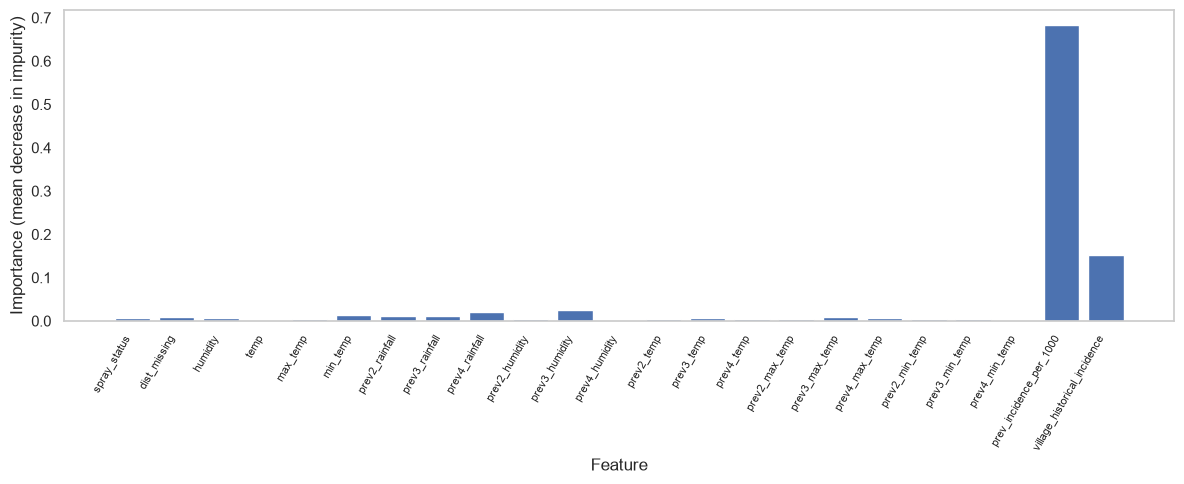

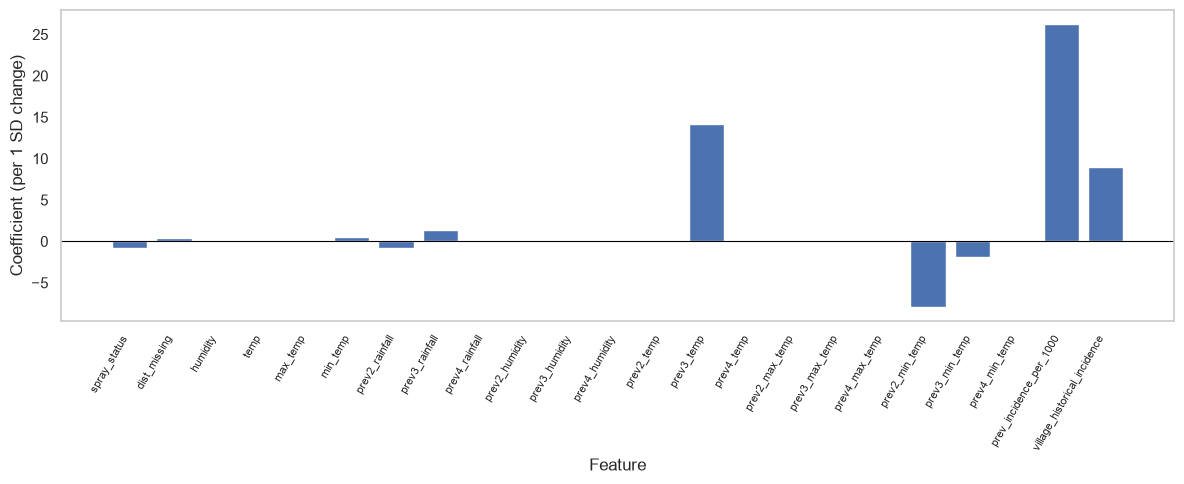

Features kept by Lasso: 10 of 23


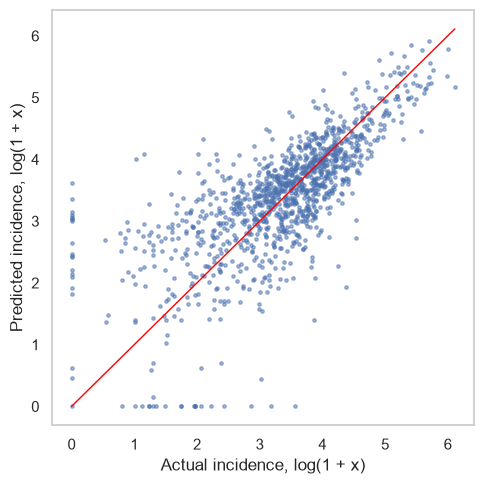

In [35]:
plt.rcParams['axes.grid'] = False
# ===== Final figures (run at 0.7 with the feature) =====
labels = [c.replace('mpi', 'village_historical_incidence') for c in X_train.columns]

# Figure 1: Random forest feature importance
plt.figure(figsize=(12, 5))
plt.bar(labels, model.feature_importances_)
plt.xlabel('Feature'); plt.ylabel('Importance (mean decrease in impurity)')
plt.xticks(rotation=60, ha='right', fontsize=8)
plt.tight_layout(); plt.savefig('fig1_rf_importance.png', dpi=300, bbox_inches='tight'); plt.show()

# Figure 2: Lasso coefficients (standardized features)
plt.figure(figsize=(12, 5))
plt.bar(labels, lasso.best_estimator_.coef_.ravel())
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Feature'); plt.ylabel('Coefficient (per 1 SD change)')
plt.xticks(rotation=60, ha='right', fontsize=8)
plt.tight_layout(); plt.savefig('fig2_lasso_coefficients.png', dpi=300, bbox_inches='tight'); plt.show()
print('Features kept by Lasso:', int((lasso.best_estimator_.coef_ != 0).sum()), 'of', len(labels))

# Figure 3: Lasso predicted vs actual (log scale for visibility)
y_act = np.log1p(np.ravel(y_test))
y_pred = np.log1p(np.clip(np.ravel(lasso.predict(X_test_scaled)), 0, None))
plt.figure(figsize=(5, 5))
plt.scatter(y_act, y_pred, s=6, alpha=0.5)
lim = [0, max(y_act.max(), y_pred.max())]
plt.plot(lim, lim, color='red', linewidth=1)
plt.xlabel('Actual incidence, log(1 + x)'); plt.ylabel('Predicted incidence, log(1 + x)')
plt.tight_layout(); plt.savefig('fig3_lasso_scatter.png', dpi=300, bbox_inches='tight'); plt.show()

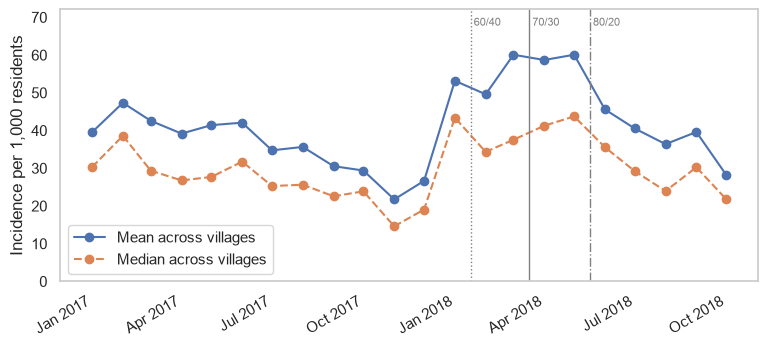

In [36]:
import matplotlib.dates as mdates
plt.rcParams['axes.grid'] = False
m = df.copy(); m['visit_month'] = pd.to_datetime(m['visit_month'])
monthly = m.groupby('visit_month')['incidence_per_1000'].agg(['mean', 'median'])
months = monthly.index

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(months, monthly['mean'], marker='o', label='Mean across villages')
ax.plot(months, monthly['median'], marker='o', linestyle='--', label='Median across villages')
ax.set_ylim(0, monthly['mean'].max() * 1.2)
for r, ls in [(0.6, ':'), (0.7, '-'), (0.8, '-.')]:
    start = months[int(len(months) * r)] - pd.Timedelta(days=15)
    ax.axvline(start, color='gray', linestyle=ls, linewidth=1)
    ax.text(start + pd.Timedelta(days=3), ax.get_ylim()[1] * 0.94,
            f'{round(r*100)}/{round((1-r)*100)}', fontsize=8, color='gray')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
ax.set_ylabel('Incidence per 1,000 residents')
ax.legend(loc='lower left')
plt.savefig('fig_monthly_incidence.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:
from sklearn.base import clone
 
tr = df[chrono(1)]
cols = ['incidence_per_1000', 'avg_distance_to_health_facility_km', 'positivity_rate', 'spray_status']

d = df.sort_values(['village_code', 'visit_month'])
vals = pd.DataFrame(index=d.index)
for col in ['incidence_per_1000', 'positivity_rate']:
    g = d.groupby('village_code')[col]
    vals[col] = ((g.cumsum() - d[col]) / g.cumcount().replace(0, np.nan)).fillna(tr[col].mean())
vals['avg_distance_to_health_facility_km'] = d['avg_distance_to_health_facility_km']
vals['spray_status'] = d['spray_status']
vals = vals.loc[df.index]
village_avg = tr.groupby('village_code')[cols].mean()
 
def make_version(weights, log_inc=False):
    v, va = vals.copy(), village_avg.copy()
    if log_inc:
        v['incidence_per_1000'] = np.log1p(v['incidence_per_1000'])
        va['incidence_per_1000'] = np.log1p(va['incidence_per_1000'])
    out = 0.0
    for col, w in weights.items():
        lo, hi = va[col].min(), va[col].max()
        out = out + w * (v[col] - lo) / (hi - lo)
    return out
 
versions = {
    'Original composite': make_version({'incidence_per_1000': 4, 'avg_distance_to_health_facility_km': 1.5,
                                        'positivity_rate': 1.5, 'spray_status': -0.3}),
    'Equal weights':      make_version({'incidence_per_1000': 1, 'avg_distance_to_health_facility_km': 1,
                                        'positivity_rate': 1, 'spray_status': -1}),
    'Log-equal':          make_version({'incidence_per_1000': 1, 'avg_distance_to_health_facility_km': 1,
                                        'positivity_rate': 1, 'spray_status': -1}, log_inc=True),
    'Past incidence only': make_version({'incidence_per_1000': 1}),
}

print('CHECK 1 - max difference from notebook 2 mpi (must be ~0):',
      float((versions['Past incidence only'] - df['mpi']).abs().max()))

y_tr, y_true = np.ravel(y_train), np.ravel(y_test)
villages = df[~chrono(1)]['village_code'].values
uv = np.unique(villages)
rows_of = {v: np.where(villages == v)[0] for v in uv}
rng = np.random.default_rng(0)
samples = [np.concatenate([rows_of[v] for v in rng.choice(uv, len(uv))]) for _ in range(2000)]
 
models = [('KNN', knn), ('LR', linear), ('RF', model), ('DT', dt),
          ('Ridge', ridge), ('Lasso', lasso), ('ElasticNet', elasticnet)]

base = [c for c in X_train.columns if c != 'mpi']
sc0 = StandardScaler().fit(X_train[base])
Xtr0, Xte0 = sc0.transform(X_train[base]), sc0.transform(X_test[base])
p_without = {n: np.ravel(clone(e).fit(Xtr0, y_tr).predict(Xte0)) for n, e in models}
 
rows = []
for vname, feat in versions.items():
    Xtr_v = X_train.assign(mpi=feat.loc[X_train.index].values)
    Xte_v = X_test.assign(mpi=feat.loc[X_test.index].values)
    sc = StandardScaler().fit(Xtr_v)
    Xtr_s, Xte_s = sc.transform(Xtr_v), sc.transform(Xte_v)
    for n, e in models:
        p_with = np.ravel(clone(e).fit(Xtr_s, y_tr).predict(Xte_s))
        pw = p_without[n]
        boot = [100 * (r2_score(y_true[i], p_with[i]) - r2_score(y_true[i], pw[i])) for i in samples]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        rows.append({'Version': vname, 'Model': n,
                     'R2 without': 100 * r2_score(y_true, pw), 'R2 with': 100 * r2_score(y_true, p_with),
                     'Gain': 100 * (r2_score(y_true, p_with) - r2_score(y_true, pw)),
                     'CI low': lo, 'CI high': hi})
 
res = pd.DataFrame(rows)
print('\nCHECK 2 - the "Past incidence only" rows must match the with/without bootstrap table above.\n')
for vname in versions:
    print(f'=== {vname} ===')
    print(res[res['Version'] == vname].drop(columns='Version').round(2).to_string(index=False), '\n')

CHECK 1 - max difference from notebook 2 mpi (must be ~0): 2.220446049250313e-16

CHECK 2 - the "Past incidence only" rows must match the with/without bootstrap table above.

=== Original composite ===
     Model  R2 without  R2 with   Gain  CI low  CI high
       KNN       59.74    55.18  -4.56  -10.39     2.88
        LR       28.44    29.54   1.10    0.61     1.83
        RF       63.11    60.76  -2.35   -5.44     1.24
        DT       32.73    -5.28 -38.01  -58.09   -19.98
     Ridge       67.38    67.81   0.43   -0.43     1.36
     Lasso       65.79    66.43   0.65    0.20     1.21
ElasticNet       68.29    66.26  -2.03   -3.80    -1.13 

=== Equal weights ===
     Model  R2 without  R2 with   Gain  CI low  CI high
       KNN       59.74    56.68  -3.05   -6.20    -0.69
        LR       28.44    28.32  -0.12   -0.24    -0.02
        RF       63.11    59.59  -3.52   -5.39    -1.41
        DT       32.73    -1.80 -34.53  -63.22   -16.44
     Ridge       67.38    67.37  -0.00   -0.08

In [38]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
import warnings; from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

coefs = pd.Series(np.ravel(lasso.best_estimator_.coef_), index=X_train.columns)
print(coefs.round(3).to_string())
print('Kept:', (coefs != 0).sum(), 'of', len(coefs)); print('Removed:', list(coefs[coefs == 0].index))

tr = df[chrono(1)]
s = df.assign(_m=pd.to_datetime(df['visit_month'])).sort_values(['village_code', '_m'])
g = s.groupby('village_code')['positivity_rate']
past_pos = ((g.cumsum() - s['positivity_rate']) / g.cumcount().replace(0, np.nan)).reindex(df.index)
past_pos_tr = past_pos.loc[tr.index].fillna(tr['positivity_rate'].mean())
y_tr = np.ravel(y_train); base = X_train.drop(columns=['mpi'])
grid = lambda: GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
                            {'lasso__alpha': np.logspace(-3, 2, 25)}, cv=cv_splits, scoring='r2')
for name, cols in [('Past incidence only', {'mpi': tr['mpi']}),
                   ('Components as separate features', {'mpi': tr['mpi'],
                    'distance': tr['avg_distance_to_health_facility_km'], 'past_positivity': past_pos_tr})]:
    X = base.assign(**{k: v.values for k, v in cols.items()})
    gs = grid().fit(X, y_tr)
    lr = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y_tr, cv=cv_splits, scoring='r2').mean()
    print(f'{name}: Lasso val R2 {100*gs.best_score_:.2f} | LR val R2 {100*lr:.2f}')
comp = ['mpi', 'distance', 'past_positivity', 'spray_status']
print('Learned Lasso weights:\n', pd.Series(gs.best_estimator_[-1].coef_, index=X.columns)[comp].round(2))

spray_status               -0.803
dist_missing                0.464
humidity                    0.000
temp                        0.000
max_temp                   -0.000
min_temp                    0.574
prev2_rainfall             -0.752
prev3_rainfall              1.344
prev4_rainfall              0.000
prev2_humidity             -0.000
prev3_humidity             -0.000
prev4_humidity              0.000
prev2_temp                 -0.000
prev3_temp                 14.131
prev4_temp                 -0.000
prev2_max_temp              0.000
prev3_max_temp             -0.000
prev4_max_temp              0.000
prev2_min_temp             -7.904
prev3_min_temp             -1.829
prev4_min_temp             -0.000
prev_incidence_per_1000    26.239
mpi                         8.996
Kept: 10 of 23
Removed: ['humidity', 'temp', 'max_temp', 'prev4_rainfall', 'prev2_humidity', 'prev3_humidity', 'prev4_humidity', 'prev2_temp', 'prev4_temp', 'prev2_max_temp', 'prev3_max_temp', 'prev4_max_temp', 'prev4_